In [2]:
import pathlib
import pathlib._local
from fastai.vision.all import *

# Fix Linux PosixPath on Windows in Python 3.13
pathlib.PosixPath = pathlib.WindowsPath
pathlib._local.PosixPath = pathlib.WindowsPath

learn_inf = load_learner('model.pkl')
print("Model loaded successfully!")


Model loaded successfully!


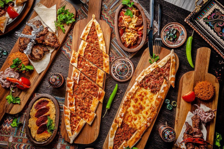

In [9]:
img = PILImage.create('turkish_food_2.jpg')
img.to_thumb(224, 224)


In [10]:
pred, pred_idx, probs = learn_inf.predict(img)
print(f"Prediction: {pred} ({probs[pred_idx]:.2%})")


Prediction: turkish_food (85.49%)


In [11]:
import ipywidgets as widgets

upload_btn = widgets.FileUpload(
    accept='image/*',
    multiple=False
)

upload_btn

FileUpload(value=(), accept='image/*', description='Upload')

In [12]:
classify_btn = widgets.Button(
    description='Classify',
    button_style='success',
    icon='check'
)

classify_btn

Button(button_style='success', description='Classify', icon='check', style=ButtonStyle())

In [13]:
output = widgets.Output()

output

Output()

In [25]:
# 2. Define the classification logic
def on_click_classify(change):
    with output:
        clear_output()
        if not upload_btn.value:
            print("Please upload an image first!")
            return
        
        # Extract uploaded image bytes (ipywidgets v8+ returns a tuple of dicts)
        uploaded_file = upload_btn.value[0]
        img = PILImage.create(uploaded_file['content'].tobytes())
        
        # Display thumbnail
        display(img.to_thumb(224, 224))
        
        # Run inference using your loaded fastai learner
        pred, pred_idx, probs = learn_inf.predict(img)
        print(f"Prediction: {pred} ({probs[pred_idx]:.2%})")

In [27]:
# 1. Define the widgets (including the instruction header)
instructions = widgets.HTML(
    value="""
    <h3>Food Image Classifier</h3>
    <p><b>Instructions:</b></p>
    <ol>
        <li>Click <b>Upload</b> to select a food image from your device.</li>
        <li>Click <b>Classify</b> to predict the cuisine type.</li>
    </ol>
    """
)

In [28]:
# 3. Attach the event handler and display the app
classify_btn.on_click(on_click_classify)
app = widgets.VBox([instructions, upload_btn, classify_btn, output])
display(app)